# 05 · 综合对比与参数调优

本笔记在统一的模拟数据上横向对比 CCA / FBCCA / ensemble TRCA，回答比赛中最实际的
几个问题：

- 信号**窗口长度**取多少？（越短越快、越长越准，需要权衡）
- 谐波个数怎么选？
- 如何用 **ITR（信息传输率）**衡量系统速度？
- 噪声增强时三种方法各自的表现？

为了拉开差距，本笔记使用**较强噪声**（noise=4）的模拟数据。注意：本模拟完全
符合 CCA 的谐波模型，所以 CCA 表现接近理论最优；真实数据上 FBCCA/TRCA 的相对
优势更明显，可用 `examples/run_benchmark.py` 在清华 Benchmark 上验证。

In [1]:
# 导入数值计算、绘图和工程模块，并设置 notebook 的显示参数

from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))  # 让 notebook 能 import 上级目录的 ssvep 包
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.unicode_minus': False})
np.set_printoptions(precision=3, suppress=True)
print('环境就绪，工程路径已加入 sys.path')

环境就绪，工程路径已加入 sys.path


In [2]:
# 定义模拟 SSVEP 数据生成函数，用于统一比较不同分类算法

def make_ssvep(n_classes=8, n_ch=9, fs=250, duration=3.0, n_trials=8,
               noise=0.6, seed=0):
    '''生成模拟 SSVEP 数据：基频+2/3 次谐波经固定空间混合，加高斯噪声。
    返回 trials(n_trials*n_classes, n_ch, T), labels, freqs。'''
    rng = np.random.default_rng(seed)
    freqs = np.arange(8.0, 8.0 + n_classes)
    T = int(fs * duration)
    t = np.arange(T) / fs
    mixing = rng.normal(size=(n_ch, 3))          # 谐波源 -> 通道 的空间混合
    phases = rng.uniform(0, 2*np.pi, size=(n_classes, 3))
    X, y = [], []
    for k, f in enumerate(freqs):
        src = np.vstack([np.sin(2*np.pi*h*f*t + phases[k, h-1]) for h in (1, 2, 3)])
        clean = mixing @ src
        for _ in range(n_trials):
            X.append(clean + noise*rng.normal(size=(n_ch, T)))
            y.append(k)
    return np.array(X), np.array(y), freqs

In [3]:
# 生成强噪声、多类别试次，并整理成类别优先的数据结构

from ssvep import CCAClassifier, FBCCAClassifier, TRCAClassifier
fs = 250
trials, labels, freqs = make_ssvep(duration=4.0, n_trials=8, noise=4.0, seed=2)
xcls = trials.reshape(8, 8, 9, trials.shape[-1])   # [class, trial, ch, T]
print('数据：', trials.shape, '（每类 8 个 trial，4 秒/片段，强噪声）')

数据： (64, 9, 1000) （每类 8 个 trial，4 秒/片段，强噪声）


## 一、窗口长度 tw 对正确率的影响

窗口越短，单次选择越快（ITR 越高），但可用的周期数越少、正确率越低。
TRCA 采用留一 trial 交叉验证；每个条件取 3 个随机种子平均。

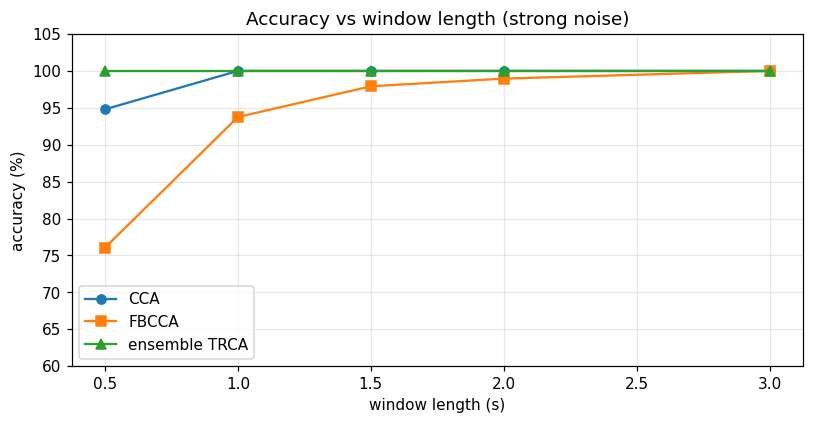

tw = [0.5, 1.0, 1.5, 2.0, 3.0]
CCA  : [ 94.8 100.  100.  100.  100. ]
FBCCA: [ 76.   93.8  97.9  99.  100. ]
TRCA : [100. 100. 100. 100. 100.]


In [4]:
# 定义 TRCA 留一试次验证，并比较不同时间窗下三种方法的准确率

def trca_loro_acc(xcls, w):
    # xcls 的形状为 (类别, trial, 通道, 时间)；w 是保留的时间点数。
    accs = []
    n_block = xcls.shape[1]
    # 轮流把一个 trial 当测试集，其余 trial 用于训练，最后平均各轮准确率。
    for b in range(n_block):
        tr_blocks = [i for i in range(n_block) if i != b]
        # 截取前 w 个采样点；拼接剩余 trial，形成训练数据 (trial, 通道, 时间)。
        trX = np.concatenate([xcls[:, i][..., :w] for i in tr_blocks], axis=0)
        trY = np.tile(np.arange(8), n_block-1)
        # 留出的 block 含每类一个试次，所以测试标签依次是 0 到 7。
        teX = xcls[:, b][..., :w]; teY = np.arange(8)
        m = TRCAClassifier(8, ensemble=True).fit(trX, trY)
        accs.append((m.predict_batch(teX) == teY).mean()*100)
    return np.mean(accs)

tws = [0.5, 1.0, 1.5, 2.0, 3.0]
acc_cca, acc_fb, acc_tr = [], [], []
for tw in tws:
    a1, a2, a3 = [], [], []
    for seed in range(3):
        X, y, fr = make_ssvep(duration=4.0, n_trials=8, noise=4.0, seed=seed)
        xc = X.reshape(8, 8, 9, X.shape[-1])
        w = int(tw*fs)
        a1.append((CCAClassifier(fr, fs).predict_batch(X[..., :w]) == y).mean()*100)
        a2.append((FBCCAClassifier(fr, fs).predict_batch(X[..., :w]) == y).mean()*100)
        a3.append(trca_loro_acc(xc, w))
    acc_cca.append(np.mean(a1)); acc_fb.append(np.mean(a2)); acc_tr.append(np.mean(a3))
plt.figure(figsize=(7.5, 3.8))
plt.plot(tws, acc_cca, 'o-', label='CCA')
plt.plot(tws, acc_fb, 's-', label='FBCCA')
plt.plot(tws, acc_tr, '^-', label='ensemble TRCA')
plt.xlabel('window length (s)'); plt.ylabel('accuracy (%)')
plt.ylim(60, 105); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.title('Accuracy vs window length (strong noise)')
plt.show()
print('tw =', tws)
print('CCA  :', np.round(acc_cca, 1))
print('FBCCA:', np.round(acc_fb, 1))
print('TRCA :', np.round(acc_tr, 1))

可以看到：窗口越短正确率越低（FBCCA 在短窗口还受子带滤波边缘效应影响）；
TRCA 因利用了同类训练片段，在强噪声下依然稳定。

## 二、谐波个数 $N_h$ 的影响

在强噪声、0.5 s 短窗口（5 个随机种子平均）下扫描谐波数。

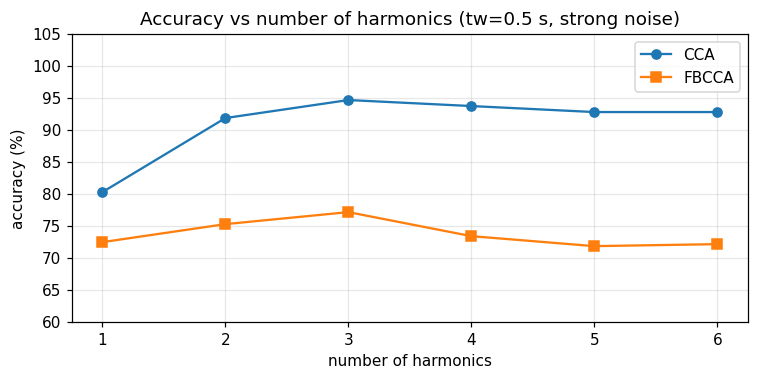

最佳谐波数：CCA = 3, FBCCA = 3


In [5]:
# 扫描参考信号谐波数量，比较 CCA 与 FBCCA 的分类准确率

nhs = range(1, 7)
a_cca, a_fb = [], []
w = int(0.5*fs)
for nh in nhs:
    c1, c2 = [], []
    for seed in range(5):
        X, y, fr = make_ssvep(noise=4.0, duration=2.0, seed=seed)
        c1.append((CCAClassifier(fr, fs, n_harmonics=nh).predict_batch(X[..., :w]) == y).mean()*100)
        c2.append((FBCCAClassifier(fr, fs, n_harmonics=nh).predict_batch(X[..., :w]) == y).mean()*100)
    a_cca.append(np.mean(c1)); a_fb.append(np.mean(c2))
plt.figure(figsize=(7, 3.4))
plt.plot(list(nhs), a_cca, 'o-', label='CCA')
plt.plot(list(nhs), a_fb, 's-', label='FBCCA')
plt.xlabel('number of harmonics'); plt.ylabel('accuracy (%)')
plt.ylim(60, 105); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.title('Accuracy vs number of harmonics (tw=0.5 s, strong noise)')
plt.show()
print('最佳谐波数：CCA = %d, FBCCA = %d'
      % (1+int(np.argmax(a_cca)), 1+int(np.argmax(a_fb))))

## 三、ITR：信息传输率

BCI 系统不只看正确率，还要看速度。每个 trial 传输的信息量（bit）为

$$B = \log_2 K + P\log_2 P + (1-P)\log_2\frac{1-P}{K-1}$$

其中 $K$ 为类别数、$P$ 为正确率；ITR（bit/min）= $B\cdot 60/t_w$。
正确率为 100% 时约定两项 $0\log 0 = 0$，此时 $B=\log_2 K$。

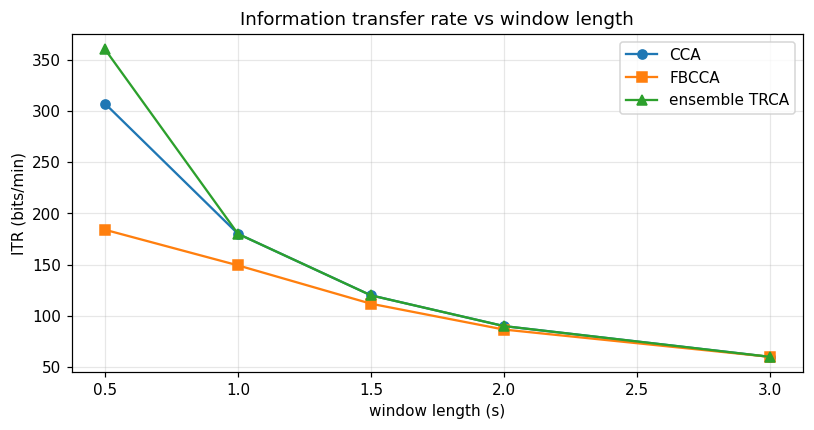

各方法 ITR 最高的窗口长度（s）：
CCA = 0.5  FBCCA = 0.5  TRCA = 0.5


In [6]:
# 根据准确率、类别数和时间窗计算信息传输率（ITR）

def itr(acc_pct, K, tw):
    # 把百分数准确率换成 0 到 1 之间的概率；ITR 公式使用概率。
    P = np.asarray(acc_pct)/100.0
    # B 是每个试次的信息量；再按窗口时长换算为每分钟的信息传输率。
    B = np.log2(K) + np.where(P == 1, 0.0, P*np.log2(P + 1e-12)) \
        + (1-P)*np.log2((1-P)/(K-1) + 1e-12)
    # 理论信息量不能为负；乘 60/tw，把每次选择换算成 bits/min。
    return np.maximum(B, 0)*60.0/np.asarray(tw)

plt.figure(figsize=(7.5, 3.8))
plt.plot(tws, itr(acc_cca, 8, tws), 'o-', label='CCA')
plt.plot(tws, itr(acc_fb, 8, tws), 's-', label='FBCCA')
plt.plot(tws, itr(acc_tr, 8, tws), '^-', label='ensemble TRCA')
plt.xlabel('window length (s)'); plt.ylabel('ITR (bits/min)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.title('Information transfer rate vs window length')
plt.show()
print('各方法 ITR 最高的窗口长度（s）：')
print('CCA =', tws[int(np.argmax(itr(acc_cca, 8, tws)))],
      ' FBCCA =', tws[int(np.argmax(itr(acc_fb, 8, tws)))],
      ' TRCA =', tws[int(np.argmax(itr(acc_tr, 8, tws)))])

ITR 由正确率与窗口长度共同决定。本模拟在 0.5 s 时仍有很高正确率，因此 ITR 随
窗口缩短而升高；但在**真实密集频率**场景（如清华 Benchmark 40 个目标、间隔仅
0.2 Hz）中，短窗口正确率会明显下降，ITR 峰值通常出现在 1~2 s，需要在真实数据上
实测。此外实际系统还要计入视线切换时间（约 0.5 s），分母应使用 $t_w + t_{shift}$。

## 四、混淆矩阵

看错误集中在哪些类别。以 FBCCA、1.5 s 窗口、强噪声为例（此时存在少量错误）。

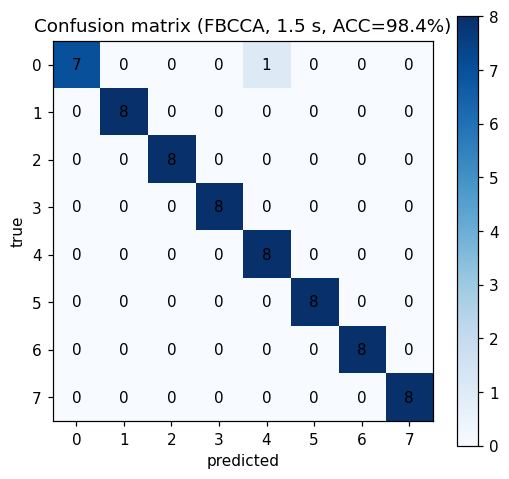

In [7]:
# 汇总 FBCCA 预测结果并绘制混淆矩阵，查看各类别的分类情况

w = int(1.5*fs)
pred = FBCCAClassifier(freqs, fs).predict_batch(trials[..., :w])
acc = (pred == labels).mean()*100
cm = np.zeros((8, 8), dtype=int)
# 混淆矩阵的行是真实类别、列是预测类别；对角线是预测正确的数量。
for p, t in zip(pred, labels):
    cm[t, p] += 1
plt.figure(figsize=(5, 4.5))
plt.imshow(cm, cmap='Blues', vmin=0); plt.colorbar()
plt.xlabel('predicted'); plt.ylabel('true')
plt.title(f'Confusion matrix (FBCCA, 1.5 s, ACC={acc:.1f}%)')
for i in range(8):
    for j in range(8):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout(); plt.show()

## 五、噪声鲁棒性对比（三种方法）

逐步增大噪声（3 个随机种子平均），观察正确率下降速度。TRCA 用留一 trial 交叉验证。

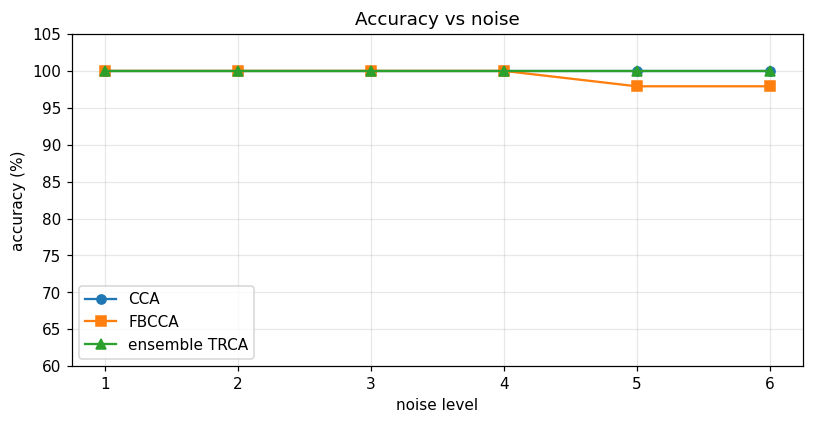

noise: [1, 2, 3, 4, 5, 6]
CCA  : [100. 100. 100. 100. 100. 100.]
FBCCA: [100.  100.  100.  100.   97.9  97.9]
TRCA : [100. 100. 100. 100. 100. 100.]


In [8]:
# 在不同噪声水平下比较 CCA、FBCCA 和集成 TRCA 的准确率

noise_levels = [1, 2, 3, 4, 5, 6]
a_cca, a_fb, a_tr = [], [], []
for nz in noise_levels:
    c1, c2, c3 = [], [], []
    for seed in range(3):
        X, y, fr = make_ssvep(duration=3.0, n_trials=8, noise=nz, seed=seed)
        xc = X.reshape(8, 8, 9, X.shape[-1])
        c1.append((CCAClassifier(fr, fs).predict_batch(X) == y).mean()*100)
        c2.append((FBCCAClassifier(fr, fs).predict_batch(X) == y).mean()*100)
        c3.append(trca_loro_acc(xc, X.shape[-1]))
    a_cca.append(np.mean(c1)); a_fb.append(np.mean(c2)); a_tr.append(np.mean(c3))
plt.figure(figsize=(7.5, 3.8))
plt.plot(noise_levels, a_cca, 'o-', label='CCA')
plt.plot(noise_levels, a_fb, 's-', label='FBCCA')
plt.plot(noise_levels, a_tr, '^-', label='ensemble TRCA')
plt.xlabel('noise level'); plt.ylabel('accuracy (%)')
plt.ylim(60, 105); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.title('Accuracy vs noise')
plt.show()
print('noise:', noise_levels)
print('CCA  :', np.round(a_cca, 1))
print('FBCCA:', np.round(a_fb, 1))
print('TRCA :', np.round(a_tr, 1))

## 六、比赛调参清单

1. **先跑通保底**：CCA / FBCCA 无需训练，拿到数据 30 分钟内先提交一版。
2. **确定频率表**：8 个类别的真实刺激频率以官方数据/说明为准，改 `freqs`。
3. **调窗口长度**：在测试数据上按 0.5 / 1.0 / 1.5 / 2.0 s 网格评估正确率与 ITR。
4. **调谐波数与子带**：$N_h\in[3,5]$，FBCCA 子带数 3~5，按交叉验证结果定。
5. **有校准数据就上 TRCA**：留一 block 交叉验证，训练 trial 越多越好。
6. **预处理固定**：50 Hz 陷波、6~80 Hz 带通、统一扣 0.14 s 延迟。
7. 每次提升都重新提交（以最后一次为准），但**保留每个版本的结果与日志**。

## 七、深度学习方向（报告创新点）

- **EEGNet 式轻量 CNN**：时间卷积 + 深度可分离空间卷积，小数据也能训练；
- **Conv-CA / CCNN**：把 CCA 的参考信号相关思想写进网络；
- **Transformer / 频域网络**：对多通道时序做自注意力或直接在频谱上分类。

深度学习需要 GPU（d2l 环境已装 CUDA 版 PyTorch）与带标签数据，建议备赛期在清华
Benchmark 上调好并固化，比赛当天作为补充方案，不要替代保底基线。所有网络结构
必须自主实现，不能调用第三方成品脑电解码模块。